In [50]:
from pathlib import Path
import numpy as np, pandas as pd, mne
import matplotlib.pyplot as plt
mne.set_log_level("WARNING")


root = Path("data/R5_mini_L100_bdf")
inv = pd.DataFrame({"path": sorted(root.glob("sub-*/eeg/*_eeg.bdf"))})
inv["subject"] = inv.path.map(lambda p: p.name.split("_")[0])
inv["task"] = inv.path.map(lambda p: p.name.split("task-")[1].split("_")[0])

print(inv.groupby("task").size())                                   # enregistrements par tâche
ccd = inv[inv.task == "contrastChangeDetection"]
print(ccd.groupby("subject").size().value_counts())                 # runs CCD par sujet

print(list(root.glob("*.tsv")))                                     # participants.tsv est-il là ?

task
DespicableMe               20
DiaryOfAWimpyKid           20
FunwithFractals            20
RestingState               20
ThePresent                 20
contrastChangeDetection    60
seqLearning6target          6
seqLearning8target         14
surroundSupp               40
symbolSearch               20
dtype: int64
3    20
Name: count, dtype: int64
[PosixPath('data/R5_mini_L100_bdf/participants.tsv')]


20 sujet et 3 run chacun de 60 enregistrements

In [51]:
! pip install pandas

python(44076) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [52]:
import pandas as pd 

participants = pd.read_csv(root / "participants.tsv", sep="\t")
print('1')
print(participants.shape)
print('2')
print(participants.columns.tolist())
print('3')
print(participants.head())
print('4')
print(participants.isna().sum())  
print('5')
print(participants.describe())
print('6')
print(participants.value_counts())


1
(20, 24)
2
['participant_id', 'release_number', 'sex', 'age', 'ehq_total', 'commercial_use', 'full_pheno', 'p_factor', 'attention', 'internalizing', 'externalizing', 'RestingState', 'DespicableMe', 'FunwithFractals', 'ThePresent', 'DiaryOfAWimpyKid', 'contrastChangeDetection_1', 'contrastChangeDetection_2', 'contrastChangeDetection_3', 'surroundSupp_1', 'surroundSupp_2', 'seqLearning6target', 'seqLearning8target', 'symbolSearch']
3
     participant_id release_number sex      age  ehq_total commercial_use  \
0  sub-NDARAH793FBF             R5   M   9.3427      60.03            Yes   
1  sub-NDARAJ689BVN             R5   F   5.4878      46.69            Yes   
2  sub-NDARAP785CTE             R5   M   8.7157     100.05            Yes   
3  sub-NDARAU708TL8             R5   M  12.0751     100.05            Yes   
4  sub-NDARBE091BGD             R5   M   7.4098     -13.34            Yes   

  full_pheno  p_factor  attention  internalizing  ...  ThePresent  \
0         No     0.317      0.

# 1. Contexte : les données HBN-EEG

Les données viennent du **Healthy Brain Network (HBN-EEG)** et sont utilisées pour l'EEG Foundation Challenge : plus de 3 000 participants, enregistrés en EEG pendant 6 tâches cognitives.

| Catégorie | Tâches |
|---|---|
| Passives | Resting State, Surround Suppression, Movie Watching (4 films) |
| Actives | Contrast Change Detection (CCD), Sequence Learning, Symbol Search |

**Format** : EEG à **129 canaux**, signaux filtrés entre 0,5 et 50 Hz puis rééchantillonnés à **100 Hz**, fichiers `.bdf`, organisation BIDS (un dossier `sub-XXXX/eeg/` par sujet).

**Échantillon étudié** : la release mini **R5** (20 sujets), téléchargée depuis S3.

# 2. Ce que contient la release R5 mini

| Tâche | Enregistrements |
|---|---|
| contrastChangeDetection | 60 (3 runs × 20 sujets) |
| surroundSupp | 40 (2 runs × 20 sujets) |
| RestingState, 3 films, symbolSearch | 20 chacun |
| seqLearning6target / 8target | 6 + 14 = 20 (chaque sujet n'en fait qu'une des deux) |

Chaque enregistrement est accompagné d'un `_events.tsv` (événements horodatés), d'un `_channels.tsv` et d'un `.json` de métadonnées.

# 3. Les informations sur les sujets (`participants.tsv`)

20 lignes, 24 colonnes.

- **Identité** : `participant_id` (clé pour relier au dossier `sub-...`), `release_number` (R5 pour tous, inutile).
- **Démographie** : `sex`, `age` (5,5 à 18,9 ans, moyenne 10,8), `ehq_total` (score de latéralité).
- **Psychopathologie** : `p_factor`, `attention`, `internalizing`, `externalizing` (scores standardisés autour de 0, cibles de l'autre volet du challenge). 1 valeur manquante sur 20 pour chacun.
- **Disponibilité** : une colonne par tâche, valeurs `available` / `unavailable`.

Remarques : `describe()` ne résume que les colonnes numériques. Ces informations (âge, sexe...) ne font pas partie des entrées autorisées dans le challenge officiel, qui ne fournit que l'EEG.

# 4. La tâche étudiée : Contrast Change Detection (CCD)

Le sujet regarde deux disques rayés qui clignotent, l'un incliné à gauche et l'autre à droite. Après un délai aléatoire, le contraste de l'un monte pendant que celui de l'autre baisse. Le sujet appuie à gauche ou à droite pour désigner le disque dont le contraste est dominant, puis reçoit un feedback (smiley).

Ce qu'on peut en tirer :
- le clignotement continu marque l'EEG à des fréquences fixes (type **SSVEP**) ;
- le début du changement de contraste, l'appui et le feedback sont des événements datés (type **ERP**).

# 5. Le problème à résoudre (challenge 1)

**Régression** : prédire le **temps de réaction** (en secondes) à partir d'une fenêtre EEG de 2 s, soit un tableau `(129 canaux, 200 points)`.

- Cible : délai entre le début du stimulus et l'appui. **[À COMPLÉTER : colonnes des `_events.tsv` utilisées et définition exacte]**
- Métrique : RMSE.
- Difficulté principale : le modèle doit généraliser à des **sujets jamais vus** (forte variabilité inter-sujets, EEG très bruité).

# 6. Points de vigilance

- Seulement 20 sujets : scores bruités, à interpréter avec prudence.
- Les fenêtres d'un même sujet sont corrélées (et se recouvrent si le pas est inférieur à la taille de la fenêtre) : la validation croisée doit regrouper par sujet (`GroupKFold`), sinon le score est gonflé.
- Certains sujets sont écartés dans le startkit (liste `sub_rm`) : **[À COMPLÉTER : raison]**
- Valeurs manquantes à traiter dans les scores de psychopathologie, si on les utilise.

# 7. À compléter après exploration

- Colonnes et types d'événements dans `_events.tsv` : **[À COMPLÉTER]**
- Distribution du temps de réaction (forme, valeurs aberrantes, essais sans réponse) : **[À COMPLÉTER]**
- Nombre d'essais valides par sujet : **[À COMPLÉTER]**
- Qualité du signal (canaux défectueux, durées) : **[À COMPLÉTER]**

## Calcul du temps de réaction sur un enregistrement

**Les sujets.** `participants["sex"].value_counts()` : 15 garçons et 5 filles.

**Les événements.** Je lis le fichier `_events.tsv` du premier sujet (run 1 de la tâche CCD). Chaque ligne est un événement, avec sa date en secondes (`onset`). Un essai se déroule ainsi : le contraste change (`left_target` ou `right_target`), puis le sujet appuie (`left_buttonPress` ou `right_buttonPress`).

**Le temps de réaction** est la durée entre le changement de contraste et l'appui.

**Le calcul.**
1. Je garde seulement les lignes `target` et `buttonPress` (46 lignes sur 75).
2. Je calcule l'écart de temps avec la ligne précédente (`diff()` sur `onset`), que je range dans une colonne `delta`.
3. Je garde les lignes d'appui : sur ces lignes, `delta` est l'écart avec le `target` juste avant, donc le temps de réaction.
4. J'enlève les appuis dont le feedback est `non_target` (1 cas), qui ne sont pas des réponses valides.

**Vérification.** Chaque appui retenu est précédé d'un `target` (12 `right_target` et 10 `left_target` avant les 22 appuis). Le premier temps vaut 2,110 s, ce qui correspond à mon calcul à la main (112,172 − 110,062).

**Résultat.** 21 temps de réaction, entre 1,22 s et 2,36 s.

In [53]:
print(participants["sex"].value_counts())

ccd.path.iloc[0]
chemin_ev = "data/R5_mini_L100_bdf/sub-NDARAH793FBF/eeg/sub-NDARAH793FBF_task-contrastChangeDetection_run-1_events.tsv"
ev = pd.read_csv(chemin_ev, sep="\t")
#print(ev.shape)
#print(ev.columns.tolist())
print(ev.head(30))

#print(ev["value"].str.endswith("buttonPress"))
#print(ev["onset"].shift(1))
masque = (ev["value"].str.endswith("target")) | (ev["value"].str.endswith("buttonPress"))
print('la somme',masque.sum() )
sub = ev.loc[masque]
diff =sub["onset"].diff()
sub['delta']= diff

#print(sub.head(30))
masque_1 = (sub["value"].str.endswith("buttonPress"))& (sub["feedback"] != "non_target")
temps_reaction= sub.loc[masque_1,'delta']
print(sub["value"].shift(1)[masque_1].value_counts())
print(ev["feedback"].value_counts())
print(temps_reaction.head(30))



sex
M    15
F     5
Name: count, dtype: int64
      onset  duration                   value event_code     feedback
0     0.000       NaN               break cnt  break cnt          NaN
1    96.766       NaN  contrastChangeB1_start         94          NaN
2   107.240       NaN     contrastTrial_start          5          NaN
3   110.062       NaN            right_target          9          NaN
4   112.172       NaN       right_buttonPress         13  smiley_face
5   112.488       NaN     contrastTrial_start          5          NaN
6   115.290       NaN            right_target          9          NaN
7   117.160       NaN       right_buttonPress         13  smiley_face
8   117.690       NaN     contrastTrial_start          5          NaN
9   122.090       NaN            right_target          9          NaN
10  124.040       NaN       right_buttonPress         13  smiley_face
11  124.490       NaN     contrastTrial_start          5          NaN
12  130.490       NaN            right_targe

In [54]:
def f_temps_reaction(chemin):
    ev = pd.read_csv(chemin, sep="\t")
    nom = Path(chemin).name
    morceaux = nom.split("_")
    masque = (ev["value"].str.endswith("target")) | (ev["value"].str.endswith("buttonPress"))
    sub = ev.loc[masque]
    sub["subject"] = morceaux[0]
    sub["run"] = morceaux[2]
    diff =sub["onset"].diff()
    sub['rt']= diff
    sub["onset_stim"] = sub["onset"].shift(1)
    masque_1 = (sub["value"].str.endswith("buttonPress"))& (sub["feedback"] != "non_target")
    temps_reaction= sub.loc[masque_1, ["rt", "onset_stim",'run','subject']]
    return temps_reaction

print(f_temps_reaction('data/R5_mini_L100_bdf/sub-NDARAH793FBF/eeg/sub-NDARAH793FBF_task-contrastChangeDetection_run-1_events.tsv'),len(f_temps_reaction('data/R5_mini_L100_bdf/sub-NDARAH793FBF/eeg/sub-NDARAH793FBF_task-contrastChangeDetection_run-1_events.tsv')))

       rt  onset_stim    run           subject
4   2.110     110.062  run-1  sub-NDARAH793FBF
7   1.870     115.290  run-1  sub-NDARAH793FBF
10  1.950     122.090  run-1  sub-NDARAH793FBF
13  2.100     130.490  run-1  sub-NDARAH793FBF
16  1.220     135.690  run-1  sub-NDARAH793FBF
19  1.830     140.890  run-1  sub-NDARAH793FBF
22  1.862     147.690  run-1  sub-NDARAH793FBF
28  1.630     161.290  run-1  sub-NDARAH793FBF
31  1.470     168.090  run-1  sub-NDARAH793FBF
34  1.990     176.490  run-1  sub-NDARAH793FBF
39  1.540     190.090  run-1  sub-NDARAH793FBF
42  2.230     196.890  run-1  sub-NDARAH793FBF
47  1.460     210.490  run-1  sub-NDARAH793FBF
50  1.870     217.290  run-1  sub-NDARAH793FBF
53  1.860     225.690  run-1  sub-NDARAH793FBF
56  1.742     234.090  run-1  sub-NDARAH793FBF
59  1.858     239.292  run-1  sub-NDARAH793FBF
62  2.362     247.690  run-1  sub-NDARAH793FBF
65  1.702     254.490  run-1  sub-NDARAH793FBF
68  2.180     259.690  run-1  sub-NDARAH793FBF
71  1.660    

On applique la fonction sur tt les évènements

In [55]:


L = []
for release in sorted(Path("data").glob("R*_mini_L100_bdf")):
    for chemin in sorted(release.glob("sub-*/eeg/*contrastChangeDetection*_events.tsv")):
        d = f_temps_reaction(chemin)
        d["release"] = release.name
        L.append(d)

rt_all = pd.concat(L, ignore_index=True)
rt_all_s = rt_all[rt_all["rt"] > 0.5]
print(rt_all.shape, rt_all_s.shape)
print(rt_all_s.groupby("release")["subject"].nunique())



(6813, 5) (6676, 5)
release
R1_mini_L100_bdf    20
R2_mini_L100_bdf    20
R3_mini_L100_bdf    20
R4_mini_L100_bdf    20
R5_mini_L100_bdf    20
Name: subject, dtype: int64


Essais par sujet : rt_all.groupby("subject").size(). Y a-t-il un sujet avec très peu d’essais ?




In [56]:
rt_all.groupby("subject").size()

subject
sub-NDARAA948VFH    70
sub-NDARAB793GL3    83
sub-NDARAC350BZ0    71
sub-NDARAC904DMU    67
sub-NDARAD615WLJ    48
                    ..
sub-NDARGA056TMW    90
sub-NDARGB102NWJ    69
sub-NDARGH775KF5    88
sub-NDARGJ878ZP4    86
sub-NDARHA387FPM    94
Length: 100, dtype: int64

Valeurs extrêmes : rt_all["rt"].describe()

In [57]:
rt_all["rt"].describe()

count    6813.000000
mean        1.589521
std         0.388188
min         0.010000
25%         1.370000
50%         1.600000
75%         1.832000
max         2.410000
Name: rt, dtype: float64


Distribution : plt.hist(rt_all["rt"], bins=30). Est-elle regroupée autour de 1,5 à 2 s, ou y a-t-il une longue queue ?

(array([ 19.,  22.,  24.,  19.,  22.,  27.,  16.,  11.,  19.,  43.,  34.,
         82., 104., 183., 252., 375., 471., 537., 595., 645., 672., 547.,
        485., 348., 368., 226., 209., 197., 147., 114.]),
 array([0.01, 0.09, 0.17, 0.25, 0.33, 0.41, 0.49, 0.57, 0.65, 0.73, 0.81,
        0.89, 0.97, 1.05, 1.13, 1.21, 1.29, 1.37, 1.45, 1.53, 1.61, 1.69,
        1.77, 1.85, 1.93, 2.01, 2.09, 2.17, 2.25, 2.33, 2.41]),
 <BarContainer object of 30 artists>)

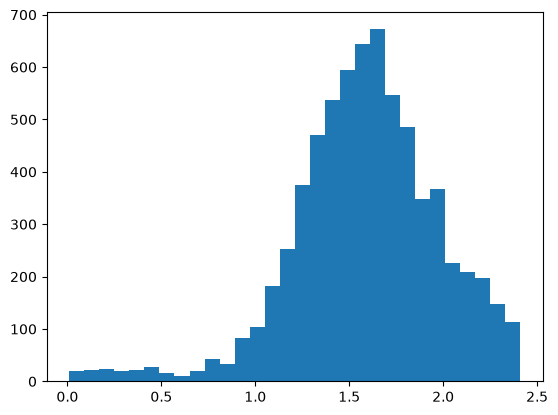

In [58]:
plt.hist(rt_all["rt"], bins=30)

Essaie louche 50 ms beaucoup trop rapide !, sub-NDARAJ689BVN ne fait que 30 enregistrements il pèsera moins dans l'apprentissage 

In [59]:
rt_all[rt_all["rt"] < 0.5]

,rt,onset_stim,run,subject,release
344,0.38,177.000,run-1,sub-NDARBH024NH2,R1_mini_L100_bdf
345,0.49,182.200,run-1,sub-NDARBH024NH2,R1_mini_L100_bdf
353,0.45,76.296,run-2,sub-NDARBH024NH2,R1_mini_L100_bdf
361,0.17,140.704,run-2,sub-NDARBH024NH2,R1_mini_L100_bdf
366,0.10,179.904,run-2,sub-NDARBH024NH2,R1_mini_L100_bdf
...,...,...,...,...,...
5933,0.49,176.592,run-3,sub-NDARBE103DHM,R5_mini_L100_bdf
6097,0.49,61.586,run-3,sub-NDARBJ674TVU,R5_mini_L100_bdf
6197,0.23,170.142,run-1,sub-NDARCA740UC8,R5_mini_L100_bdf
6201,0.43,204.142,run-1,sub-NDARCA740UC8,R5_mini_L100_bdf


In [60]:
chemin_sub ="data/R5_mini_L100_bdf/sub-NDARBE091BGD/eeg/sub-NDARBE091BGD_task-contrastChangeDetection_run-1_events.tsv"
sub_louche = pd.read_csv(chemin_sub, sep="\t")

print(sub_louche.head(50))



      onset  duration                   value event_code     feedback
0     0.000       NaN               break cnt  break cnt          NaN
1    47.608       NaN  contrastChangeB1_start         94          NaN
2    54.576       NaN     contrastTrial_start          5          NaN
3    57.374       NaN            right_target          9          NaN
4    59.784       NaN     contrastTrial_start          5          NaN
5    62.582       NaN            right_target          9          NaN
6    64.984       NaN     contrastTrial_start          5          NaN
7    69.382       NaN            right_target          9          NaN
8    70.732       NaN       right_buttonPress         13  smiley_face
9    71.212       NaN        left_buttonPress         12   non_target
10   71.784       NaN     contrastTrial_start          5          NaN
11   77.792       NaN            right_target          9          NaN
12   79.812       NaN        left_buttonPress         12     sad_face
13   80.192       Na

je pensais que ce serait dû a une erreur dans les données mais ce n'est pas le cas peut êtres un appuie anticipé 

In [61]:
for seuil in [0.2, 0.3, 0.5, 0.7]:
    print(seuil, (rt_all["rt"] < seuil).sum())

0.2 48
0.3 79
0.5 133
0.7 172


On va écarté les valeurs inf à 0.5 d'après l'histogramme et on rentre ça dans une nouvelle variable rt_all_s

In [62]:
rt_all_s = rt_all[rt_all["rt"] > 0.5]
print(rt_all_s.shape)
rt_all_s.describe()

(6676, 5)


,rt,onset_stim
count,6676.000000,6676.000000
mean,1.616554,203.281118
std,0.342052,162.353352
min,0.510000,14.424000
25%,1.390000,106.562000
50%,1.610000,156.647000
75%,1.840000,209.465000
max,2.410000,918.462000


In [63]:


raw =mne.io.read_raw_bdf("data/R5_mini_L100_bdf/sub-NDARAH793FBF/eeg/sub-NDARAH793FBF_task-contrastChangeDetection_run-1_eeg.bdf", preload=True)    
sfreq = raw.info["sfreq"]
tab = raw.get_data()
print(raw.info["sfreq"])
print(tab.shape)
print(tab)


ligne = rt_all_s.iloc[0]
onset_stim= ligne['onset_stim']
debut = int((onset_stim + 0.5) * sfreq)
fin = debut + 200
print(tab[:, debut:fin].shape)

100.0
(129, 34900)
[[ 1.30636731e-05  1.80381578e-06  1.24011199e-05 ...  7.63326929e-11
   7.63326929e-11  7.63326929e-11]
 [-4.57771381e-06 -1.91586536e-05 -9.61111118e-06 ... -2.90691870e-10
  -2.90691870e-10 -2.90691870e-10]
 [ 1.00952668e-05 -7.20613226e-06  1.44872893e-06 ... -1.07914213e-11
  -1.07914213e-11 -1.07914213e-11]
 ...
 [ 1.07207238e-04  9.20133069e-05  9.06436234e-05 ... -1.03149539e-08
  -1.03149539e-08 -1.03149539e-08]
 [ 4.55813673e-05  2.81050320e-05  2.93961236e-05 ... -9.89914000e-11
  -9.89914000e-11 -9.89914000e-11]
 [ 5.00000030e-13  5.00000030e-13  5.00000030e-13 ...  5.00000030e-13
   5.00000030e-13  5.00000030e-13]]
(129, 200)


## Découpage des fenêtres EEG

La fonction `f_fenetre(chemin, onset_stim)` découpe, pour un enregistrement, une fenêtre de signal par essai.

- **Entrée** : le chemin du fichier `.bdf` et la liste des dates de stimulus (`onset_stim`) de ce run.
- **Chargement** : le fichier est lu une seule fois, ce qui évite de recharger le signal pour chaque essai.
- **Fenêtre** : 2 s de signal, soit 200 points à 100 Hz, qui commencent 0,5 s après le stimulus. L'indice de départ est `(onset_stim + 0,5) × fréquence d'échantillonnage`, converti en entier.
- **Sortie** : un tableau `(n_essais, 129, 200)`.

Vérification sur le run 1 du premier sujet : 21 essais, soit `(21, 129, 200)`, ce qui correspond aux 21 temps de réaction valides.

In [64]:
def f_fenetre(chemin,onset_stim):
    raw = mne.io.read_raw_bdf(chemin, preload=True)
    tab = raw.get_data()
    L=[]
    sfreq = raw.info["sfreq"]
    for k in onset_stim:
        debut = int((k + 0.5) * sfreq)
        fin = debut + 200
        L.append(tab[:, debut:fin])
    return np.stack(L).astype(np.float32)
subject = "sub-NDARAH793FBF"
run = "run-1"
masque = (rt_all_s["subject"] == subject) & (rt_all_s["run"] == run)

chemin = f"data/R5_mini_L100_bdf/{subject}/eeg/{subject}_task-contrastChangeDetection_{run}_eeg.bdf"
        

print(f_fenetre(chemin,rt_all_s.loc[masque,"onset_stim"]))



[[[-2.69000907e-06 -6.70039435e-06 -2.38011671e-05 ...  1.02734321e-05
    1.17711681e-06 -1.25274419e-05]
  [ 4.59434796e-06  9.80053983e-07 -1.42936879e-05 ...  1.88455795e-06
    1.36623623e-06 -8.54887730e-06]
  [ 3.24973917e-06  2.04494472e-06 -1.26040222e-05 ... -2.96003714e-06
   -1.96099927e-06 -3.01854493e-06]
  ...
  [ 4.08280903e-06 -4.83606027e-06 -1.87399419e-05 ... -1.45671838e-05
   -2.27215787e-05 -2.52539012e-05]
  [-8.53951951e-06 -1.36372837e-05 -2.20300863e-05 ... -1.56635870e-05
   -2.23678035e-05 -2.28234276e-05]
  [ 5.00000052e-13  5.00000052e-13  5.00000052e-13 ...  5.00000052e-13
    5.00000052e-13  5.00000052e-13]]

 [[-7.10085760e-06 -7.82786901e-06 -1.33279746e-05 ... -1.47097380e-05
   -6.01467354e-06 -6.87194233e-06]
  [-8.03334751e-06 -8.32600836e-06 -1.39205331e-05 ... -1.25200404e-05
   -2.71287217e-06 -4.63959623e-06]
  [ 4.36471623e-07 -2.13554313e-06 -7.88937541e-06 ... -1.75644491e-05
   -5.43462056e-06 -6.50893526e-06]
  ...
  [-2.01706052e-06 -1.0

## Construction du jeu de données

Je rassemble les fenêtres EEG, les temps de réaction et les sujets de tous les essais valides, pour les 60 enregistrements CCD.

- **Parcours** : `groupby(["subject", "run"])` donne un groupe par run (60 au total). Pour chacun, je charge le fichier `.bdf` une seule fois et je découpe une fenêtre par essai avec `f_fenetre`.
- **Alignement** : les fenêtres, les temps de réaction (`rt`) et les sujets sont construits dans la même boucle, ce qui garantit que l'essai numéro *k* est le même dans les trois tableaux.
- **Résultat** :
  - `X_fen` : `(1206, 129, 200)`, soit 1206 fenêtres de 129 canaux et 200 points (2 s à 100 Hz) ;
  - `y` : `(1206,)`, les temps de réaction en secondes ;
  - `groupes` : `(1206,)`, le sujet de chaque essai, pour valider par sujet.
- **Vérification** : le premier essai vaut `rt = 2,11` s et vient bien de `sub-NDARAH793FBF`.
- **Sauvegarde** : les trois tableaux sont enregistrés dans `data/` (`np.save`) pour ne pas avoir à recharger les fichiers à chaque session.

In [81]:
L_rt, L_subject, L_release, L_fen = [], [], [], []

for (release, subject, run), groupe in rt_all_s.groupby(["release", "subject", "run"]):
    chemin = f"data/{release}/{subject}/eeg/{subject}_task-contrastChangeDetection_{run}_eeg.bdf"
    L_rt.append(groupe["rt"].to_numpy())
    L_subject.append(groupe["subject"].to_numpy())
    L_release.append(groupe["release"].to_numpy())
    L_fen.append(f_fenetre(chemin, groupe["onset_stim"]))

X_fen = np.concatenate(L_fen)
y = np.concatenate(L_rt)
groupes = np.concatenate(L_subject)
releases = np.concatenate(L_release)
print(X_fen.shape, y.shape, groupes.shape, releases.shape)
    


(6676, 129, 200) (6676,) (6676,) (6676,)


In [82]:
std_fen = np.median(X_fen[:, :128, :].std(axis=2), axis=1)
plat = std_fen < 1e-9
print(plat.sum(), "fenêtres plates")
print(pd.Series(groupes[plat]).value_counts())   # quels sujets sont concernés

X_fen, y, groupes, releases = X_fen[~plat], y[~plat], groupes[~plat], releases[~plat]
print(X_fen.shape, y.shape, groupes.shape, releases.shape)

63 fenêtres plates
sub-NDARCA740UC8    63
Name: count, dtype: int64
(6613, 129, 200) (6613,) (6613,) (6613,)


In [83]:
np.save("data/X_fen_5rel.npy", X_fen)
np.save("data/y_5rel.npy", y)
np.save("data/groupes_5rel.npy", groupes)
np.save("data/releases_5rel.npy", releases)

In [84]:
X_fen = np.load("data/fenetres.npy")
y = np.load("data/y.npy")
groupes = np.load("data/groupes.npy", allow_pickle=True)

print(X_fen.shape, y.shape, groupes.shape)

(6676, 129, 200) (6676,) (6676,)


X_fen contiens les 129 enregistrement de tt les patient pendans 2 s

groupes = contient groupes est un tableau de 1206 chaînes de caractères, une par essai : le nom du sujet à qui appartient cet essai.

y, de forme (1206,) : les cibles. Le temps de réaction de chaque essai, en secondes (entre 0,51 et 2,39 s).

<Axes: title={'center': 'rt'}, xlabel='sujet'>

<Figure size 640x480 with 0 Axes>

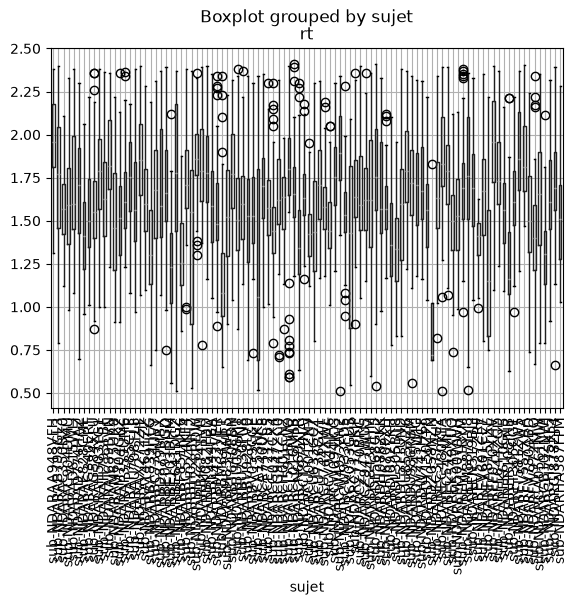

In [85]:
df = pd.DataFrame({"rt": y, "sujet": groupes})
plt.suptitle("")
df.boxplot(column="rt", by="sujet", rot=90)

### Temps de réaction par sujet

Je trace un boxplot du temps de réaction pour chacun des 20 sujets (`boxplot(column="rt", by="sujet")`).

**Observations**
- Les sujets ne sont pas au même niveau : les médianes vont d'environ 1,2 s à environ 1,85 s.
- Chaque sujet est aussi très dispersé : les boîtes couvrent souvent 0,5 s ou plus.
- Tous les sujets s'arrêtent vers 2,3 à 2,4 s.

**Conséquence.** Un modèle pourrait prédire le temps de réaction en reconnaissant le sujet, sans rien apprendre de la réaction elle-même. C'est pourquoi la validation se fait par sujet (`GroupKFold`). Avec seulement 20 sujets, le score dépendra aussi des sujets présents dans le test.

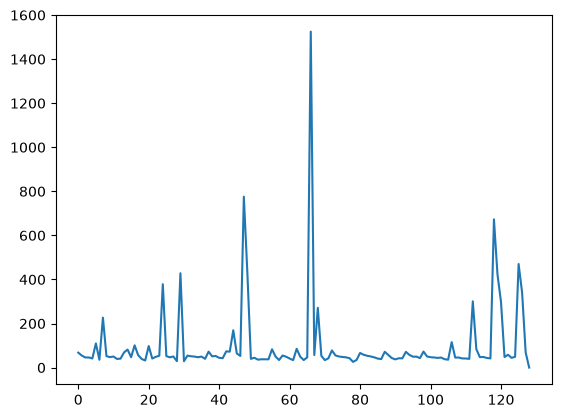

In [86]:

std_cannaux = X_fen.std(axis=2).mean(axis=0)*1e6

plt.plot(std_cannaux)


### Qualité des canaux

Pour chaque canal, je calcule l'écart-type du signal dans chaque fenêtre, puis sa moyenne sur les 1206 fenêtres, en µV.

**Observations**
- La plupart des canaux sont autour de 100 à 150 µV.
- Quelques canaux ont un écart-type 10 à 20 fois plus grand : le canal 66 (environ 2100), le 120 (environ 1400) et le 7 (environ 1050), puis les canaux 106 et 112 (environ 400 à 450).
- Le canal 128 est nul (signal plat), ce qui est cohérent avec un canal de référence, d'après la documentation du challenge.

**Interprétation provisoire.** Ces canaux sont probablement défectueux ou touchés par des artefacts, mais je ne l'ai pas encore vérifié : il reste à regarder leur signal et à voir si ce sont les mêmes chez tous les sujets.

**Conséquence.** Je les exclurai ou les traiterai à part avant de calculer les features, pour qu'ils ne dominent pas le modèle.

In [90]:
L = []
for release in sorted(Path("data").glob("R*_mini_L100_bdf")):
    p = pd.read_csv(release / "participants.tsv", sep="\t")
    p["release"] = release.name
    L.append(p)

participants = pd.concat(L, ignore_index=True)
print(participants.shape)
print(participants.columns.tolist())
print(participants.groupby("release")["age"].agg(["count", "mean", "min", "max"]))

(100, 25)
['participant_id', 'release_number', 'sex', 'age', 'ehq_total', 'commercial_use', 'full_pheno', 'p_factor', 'attention', 'internalizing', 'externalizing', 'RestingState', 'DespicableMe', 'FunwithFractals', 'ThePresent', 'DiaryOfAWimpyKid', 'contrastChangeDetection_1', 'contrastChangeDetection_2', 'contrastChangeDetection_3', 'surroundSupp_1', 'surroundSupp_2', 'seqLearning6target', 'seqLearning8target', 'symbolSearch', 'release']
                  count       mean     min      max
release                                            
R1_mini_L100_bdf     20  10.061365  6.6821  13.9757
R2_mini_L100_bdf     20  10.316390  5.5295  17.6467
R3_mini_L100_bdf     20  10.044175  5.3625  17.7890
R4_mini_L100_bdf     20   9.947310  5.7757  15.6616
R5_mini_L100_bdf     20  10.814165  5.4878  18.8954


(99, 6)
-0.305546938449826


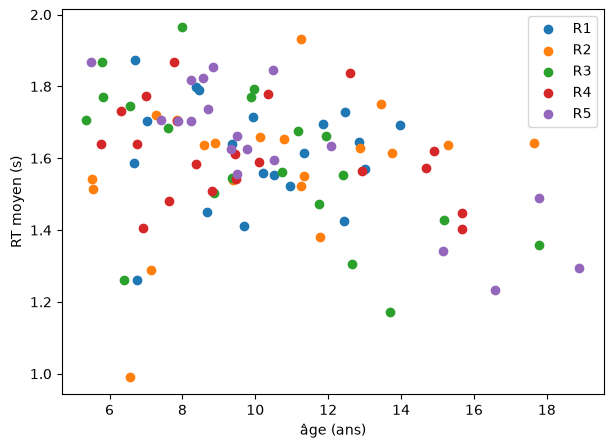

In [110]:
rt_sujet = (pd.DataFrame({"subject": groupes, "rt": y, "release": releases})
              .groupby("subject")
              .agg(rt_moyen=("rt", "mean"), n=("rt", "size"), release=("release", "first"))
              .reset_index())

aff = rt_sujet.merge(participants[["participant_id", "age"]],
                     left_on="subject", right_on="participant_id")

print(aff.shape)
print(aff[["rt_moyen", "age"]].corr().iloc[0, 1])

plt.figure(figsize=(7, 5))
for rel, g in aff.groupby("release"):
    plt.scatter(g["age"], g["rt_moyen"], label=rel[:2])
plt.xlabel("âge (ans)"); plt.ylabel("RT moyen (s)")
plt.legend(); plt.show()

In [117]:
for rel, g in aff.groupby("release"):
    print(rel, round(g["age"].corr(g["rt_moyen"]), 2))

R1_mini_L100_bdf -0.01
R2_mini_L100_bdf 0.35
R3_mini_L100_bdf -0.57
R4_mini_L100_bdf -0.3
R5_mini_L100_bdf -0.85


### Temps de réaction et âge

Je calcule le temps de réaction moyen de chaque sujet, que je relie à son âge (`participants.tsv`), puis je trace un nuage de points.

**Observations**
- Les temps de réaction baissent avec l'âge : environ 1,87 s pour le plus jeune (5,5 ans) et entre 1,23 et 1,49 s pour les plus âgés (15 à 19 ans).
- La corrélation est de −0,82 sur les 20 sujets.
- À âge égal (entre 7 et 11 ans), les sujets diffèrent déjà beaucoup (de 1,55 à 1,85 s).

**Limites.** Seulement 20 points, dont quelques sujets âgés qui pèsent beaucoup dans la pente.

**Conséquence.** Un modèle pourrait prédire le temps de réaction en repérant l'âge dans le signal EEG plutôt que la réaction elle-même. J'ajoute donc une baseline qui prédit le temps de réaction à partir de l'âge seul, que le modèle EEG doit battre.

In [124]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score

age_par_sujet = participants.set_index("participant_id")["age"]
age_fen = pd.Series(groupes).map(age_par_sujet).to_numpy().reshape(-1, 1)
print(np.isnan(age_fen).sum())   # attendu : 0

gkf = GroupKFold(n_splits=5)

for nom, mod, X_ in [("moyenne", DummyRegressor(), age_fen),
                     ("âge seul", LinearRegression(), age_fen)]:
    s = -cross_val_score(mod, X_, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    print(nom, s.mean().round(4), s.round(3))


0
moyenne 0.3431 [0.331 0.348 0.357 0.345 0.334]
âge seul 0.3355 [0.33  0.331 0.347 0.349 0.321]


### Baseline : prédire la moyenne

Je mesure d'abord ce que donne un modèle qui ignore le signal et prédit toujours la moyenne des temps de réaction d'apprentissage (`DummyRegressor`). La validation est un `GroupKFold` à 5 plis, avec le sujet comme groupe : un sujet n'est jamais à la fois dans l'apprentissage et dans le test.

**Résultat.** RMSE par pli : 0,345 ; 0,332 ; 0,423 ; 0,338 ; 0,302, soit une moyenne d'environ 0,35 s. C'est l'écart-type global des temps de réaction.

**Lecture.** C'est le chiffre à battre. L'écart entre plis (de 0,30 à 0,42) montre que le score dépend beaucoup des sujets présents dans le test, avec seulement 20 sujets.

In [125]:
from sklearn.linear_model import LinearRegression
mod = LinearRegression()
age_par_sujet = participants.set_index("participant_id")["age"]
age_essai = pd.Series(groupes).map(age_par_sujet).values.reshape(-1, 1)
#print(age_essai)   # (1206, 1)
scores = cross_val_score(mod, age_essai, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")

print(scores)

[-0.32953213 -0.3314938  -0.34702888 -0.3488758  -0.32079556]


### Baseline : l'âge seul

Je prédis le temps de réaction à partir de l'âge uniquement (`LinearRegression`), avec le même `GroupKFold` à 5 plis. L'âge de chaque essai est celui de son sujet (`participants.tsv`).

**Résultat.** RMSE par pli : 0,310 ; 0,302 ; 0,380 ; 0,274 ; 0,286, soit environ 0,31 s en moyenne, contre 0,35 s pour la moyenne seule.

**Lecture.** L'âge explique une petite part des différences, et c'est la référence à battre : un modèle EEG utile doit faire mieux que 0,31 s, sinon il a pu apprendre l'âge à partir du signal plutôt que la réaction.

### Calcul de Puissance 
L’idée : une fenêtre (129, 200) est du signal dans le temps. On veut savoir combien d’énergie elle contient dans chaque bande de fréquence (delta, theta, alpha, beta, gamma), canal par canal.

In [126]:
from scipy.signal import welch
fenetre = X_fen[0]
f, psd = welch(fenetre, fs=100, nperseg=100, axis=-1)
bandes = {"delta": (f >= 1) & (f < 4), "theta" : (f >= 4) & (f < 8), "alpha" : (f >= 8) & (f <13), "beta" : (f >= 13) & (f < 30), "gamma" : (f >= 30) & (f <= 50)}

puissance=[]
for nom, m in bandes.items():
    puissance.append(psd[:,m].mean(axis=1))
puissance= np.stack(puissance, axis=1)

print(puissance)






[[2.58636584e-11 5.23767791e-12 4.61692837e-12 2.37764496e-12
  1.09389535e-13]
 [2.63148409e-11 4.53201886e-12 3.71909925e-12 3.84148399e-12
  1.28989701e-13]
 [1.85327621e-11 2.95975093e-12 1.38807358e-12 1.07144621e-12
  7.29336500e-14]
 [1.62995919e-11 2.61191329e-12 1.43933118e-12 7.68130080e-13
  7.81423605e-14]
 [1.55472753e-11 2.28273954e-12 1.02100565e-12 7.75064258e-13
  1.06713310e-13]
 [1.67008993e-11 2.44450185e-12 7.12641426e-13 6.61982242e-13
  8.85220852e-14]
 [1.03810363e-11 1.96946561e-12 7.88038309e-13 5.20249534e-13
  5.90040305e-14]
 [2.32413446e-11 4.73527554e-12 3.19055893e-12 4.33513815e-12
  1.86131845e-13]
 [3.16604486e-11 3.85845305e-12 1.78422056e-12 4.26555839e-12
  2.42192632e-13]
 [2.62716775e-11 2.57488952e-12 1.01698045e-12 1.46799261e-12
  1.05513329e-13]
 [1.62486830e-11 2.25422805e-12 9.14650192e-13 6.34729031e-13
  6.16156567e-14]
 [1.51982454e-11 1.96416841e-12 6.41248285e-13 5.43012900e-13
  5.69606550e-14]
 [1.06018657e-11 2.31540720e-12 8.200223

In [127]:
def f_puissance(fenetre):
    f, psd = welch(fenetre, fs=100, nperseg=100, axis=-1)
    bandes = {"delta": (f >= 1) & (f < 4), "theta" : (f >= 4) & (f < 8), "alpha" : (f >= 8) & (f <13), "beta" : (f >= 13) & (f < 30), "gamma" : (f >= 30) & (f <= 50)}
    puissance=[]
    for nom, m in bandes.items():
        puissance.append(psd[:,m].mean(axis=1))
    puissance= np.stack(puissance, axis=1)
    return  puissance.ravel()

puissance = [f_puissance(fenetre) for fenetre in X_fen]
puissance = np.stack(puissance)
print(puissance.shape)
print(puissance.min())

print(puissance.max())
np.save("data/puissance.npy", puissance)
print((puissance == 0).sum())
print((puissance == 0).sum(axis=0))
print(np.where(puissance==0))
nb_zeros = (puissance == 0).sum(axis=0).reshape(129, 5)[:, 0]
print(nb_zeros)
idx = np.where(puissance[:, 125*5] == 0)[0]
np.unique(groupes[idx], return_counts=True)

for canal in [55, 106]:
    idx = np.where(puissance[:, canal*5] == 0)[0]
    print(canal, np.unique(groupes[idx], return_counts=True))

(6613, 645)
0.0
0.009224885
44248
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    2    2
    2    2    0   10   10   10   10    0   19   19   19   19    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0   19   42   42   42   42
    0   42   42   44   42   22   67   67   67   67   33   53   53   53
   53    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0   10   10   10   10  100  169  169  169  169    0
   10   10   10   10    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0   22   30   30   30   30    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    7   31   31   31   31    0    0
    0    0    0    0    0    0    0    0   

### Première famille de features : puissance par bande

Chaque fenêtre `(129 canaux, 200 points)` est résumée par sa puissance dans 5 bandes de fréquence, calculée par canal avec `scipy.signal.welch` (`fs=100`, `nperseg=100`, donc une résolution de 1 Hz).

| Bande | Fréquences |
|---|---|
| delta | 1 à 4 Hz |
| theta | 4 à 8 Hz |
| alpha | 8 à 13 Hz |
| beta | 13 à 30 Hz |
| gamma | 30 à 50 Hz |

Pour chaque bande, je moyenne la puissance sur ses fréquences. J'obtiens `(129, 5)` par fenêtre, aplati en un vecteur de 645 variables. Pour l'ensemble des essais, le tableau `puissance` fait `(1206, 645)`.

**Contrôle des valeurs.** Les puissances vont de 0 à environ 0,007.

**Canaux plats.** Il y a 6195 zéros exacts dans le tableau. Ils se trouvent sur 4 canaux :
- le canal 128, plat sur les 1206 fenêtres (la référence, d'après la documentation du challenge) ;
- les canaux 55, 106 et 125, plats sur seulement 33 fenêtres au total (10, 9 et 14).

Ces 33 fenêtres viennent de deux sujets seulement : `sub-NDARAJ689BVN` (canaux 55 et 106) et `sub-NDARBH228RDW` (canaux 125 et 106). Un zéro exact veut dire que le signal est constant sur la fenêtre, probablement une électrode déconnectée à ce moment-là. Je n'ai pas vérifié la cause.

**Décision.** on va remplacé les 0 anormale par des NaN 

In [132]:
puissance = np.stack([f_puissance(f) for f in X_fen])   # (6613, 645)
puissance_640 = puissance[:, :640].copy()               # on enlève le canal de référence
puissance_640[puissance_640 == 0] = np.nan
puissance_log = np.log10(puissance_640)

print(puissance.shape, puissance_log.shape, np.isnan(puissance_log).sum())
print(puissance_640.shape)
print(np.isnan(puissance_640).sum())

puissance_log[puissance_log < -20] = np.nan

print(np.isnan(puissance_log).sum())                  # NaN au total
print(np.nanmin(puissance_log), np.nanmedian(puissance_log), np.nanmax(puissance_log))



(6613, 645) (6613, 640) 11183
(6613, 640)
11183
46809
-19.98885 -11.6942425 -2.035039


In [134]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

resultats = []
for alpha in [1e2, 1e3, 1e4, 1e5, 1e6]:
    mod = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                    ("scaler", StandardScaler()),
                    ("reg", Ridge(alpha=alpha))])
    s = -cross_val_score(mod, puissance_log, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    resultats.append({"alpha": alpha, "rmse_moyen": s.mean(),
                      "rmse_pire": s.max(), "rmse_meilleur": s.min()})

pd.DataFrame(resultats).round(4)





,alpha,rmse_moyen,rmse_pire,rmse_meilleur
0,100.0,0.3755,0.3952,0.3564
1,1000.0,0.3550,0.3742,0.3416
2,10000.0,0.3444,0.3652,0.3309
3,100000.0,0.3422,0.3621,0.3282
4,1000000.0,0.3420,0.3595,0.3293


In [146]:
from xgboost import XGBRegressor

mod = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.5, random_state=0)
s = -cross_val_score(mod, puissance_log, y, groups=groupes, cv=gkf,
                     scoring="neg_root_mean_squared_error")
print(s.mean().round(4), s.round(3))

0.3445 [0.331 0.335 0.359 0.35  0.347]


Ici bien que la RMSE ce soit amélioré en utilisant puissance_log elle reste très élevé surtout pour certains plis elle est même plus élevé que la moyenne. 

In [147]:
print(enumerate(gkf.split(puissance_log, y, groupes)))


scores = -scores
for k , (train_idx,test_idx) in enumerate(gkf.split(puissance_log, y, groupes)):
    print(k,scores[k],np.unique(groupes[test_idx]))



0 0.3285664532141171 ['sub-NDARBD879MBX' 'sub-NDARBK082PDD' 'sub-NDARBT640EBN'
 'sub-NDARBU928LV0' 'sub-NDARCG037CX4' 'sub-NDARCH001CN2'
 'sub-NDARCU736GZ1' 'sub-NDARCW497XW2' 'sub-NDARCW933FD5'
 'sub-NDARDF568GL5' 'sub-NDARDJ092YKH' 'sub-NDARDU853XZ6'
 'sub-NDARDV245WJG' 'sub-NDAREC377AU2' 'sub-NDAREC480KFA'
 'sub-NDAREM500WWH' 'sub-NDAREM731BYM' 'sub-NDAREN519BLJ'
 'sub-NDARGA056TMW']
1 0.3549360499308774 ['sub-NDARAJ689BVN' 'sub-NDARAP785CTE' 'sub-NDARAU708TL8'
 'sub-NDARBE641DGZ' 'sub-NDARBF851NH6' 'sub-NDARBH024NH2'
 'sub-NDARBH228RDW' 'sub-NDARBM642JFT' 'sub-NDARBU730PN8'
 'sub-NDARCT974NAJ' 'sub-NDARCW094JCG' 'sub-NDARCZ947WU5'
 'sub-NDARDH670PXH' 'sub-NDARDU986RBM' 'sub-NDARFF644ZGD'
 'sub-NDARFK610GY5' 'sub-NDARFR108JNB' 'sub-NDARFT581ZW5'
 'sub-NDARFV557XAA' 'sub-NDARFV780ABD']
2 0.3633783474477131 ['sub-NDARAA948VFH' 'sub-NDARAC904DMU' 'sub-NDARAD774HAZ'
 'sub-NDARAG340ERT' 'sub-NDARAH503YG1' 'sub-NDARAM675UR8'
 'sub-NDARAM704GKZ' 'sub-NDARBA839HLG' 'sub-NDARBG574KF4'
 'sub-

Il y a au moins un sujet problèmatique dans le plis 0 et 3 

In [148]:
from sklearn.model_selection import cross_val_predict
prediction = cross_val_predict(mod, puissance_log, y, groups=groupes, cv=gkf)
print(prediction.shape)

erreur = (prediction-y)**2
print(erreur)
groupes_erreur =pd.DataFrame({"sujet": groupes, "erreur": erreur})
groupes_erreur = groupes_erreur.groupby("sujet")["erreur"].mean()
groupes_erreur = np.sqrt(groupes_erreur)
groupes_erreur = groupes_erreur.sort_values(ascending=False)
print(groupes_erreur)

(6613,)
[0.29006091 0.08392484 0.17176036 ... 0.02809878 0.10232995 0.03145146]
sujet
sub-NDARDZ058NZN    0.832588
sub-NDARCA153NKE    0.793981
sub-NDARFA815FXE    0.643103
sub-NDARFR108JNB    0.572365
sub-NDARBH024NH2    0.568149
                      ...   
sub-NDARAC350BZ0    0.230635
sub-NDARCU744XWL    0.230497
sub-NDARCH001CN2    0.226415
sub-NDARCU001ZN7    0.209506
sub-NDARDH670PXH    0.202446
Name: erreur, Length: 99, dtype: float64


Trois sujets expliquent les deux mauvais plis : AP785CTE et BJ674TVU sont dans le pli 0, BF851NH6 dans le pli 3. Les plis 1, 2 et 4 n’en contiennent aucun, et ce sont ceux à 0,45 à 0,51 s.

Ces plis « normaux » sont quand même au-dessus de la baseline (0,35 s). Retirer les trois sujets ne suffira donc pas : le modèle ne bat pas la moyenne, même sur les sujets sages.

Un RMSE de 7 s sur des temps entre 0,5 et 2,4 s, c’est un modèle linéaire qui extrapole : un sujet dont les features sont hors de la plage vue à l’apprentissage donne une prédiction énorme. AP785CTE est bien celui aux nombreuses valeurs quasi plates. Pour BF851NH6, je n’ai pas d’explication : il avait 0 valeur sous −20.

#### trouver ce qui est extrême chez ces trois sujets

In [149]:
z = (puissance_log - np.nanmean(puissance_log, axis=0)) / np.nanstd(puissance_log, axis=0)

ecart_extreme = np.nanmax(np.abs(z), axis=1)

groupes_ecart_extreme = pd.DataFrame({"sujet":groupes,"ecart":ecart_extreme})
groupes_ecart_extreme = groupes_ecart_extreme.groupby("sujet")["ecart"].agg(["median", "max"])
print(groupes_ecart_extreme)


                    median        max
sujet                                
sub-NDARAA948VFH  2.005169   3.341832
sub-NDARAB793GL3  2.486633   5.400598
sub-NDARAC350BZ0  1.920991   6.281691
sub-NDARAC904DMU  2.333145   6.824939
sub-NDARAD615WLJ  2.902714   6.928098
...                    ...        ...
sub-NDARGA056TMW  1.826535  10.439281
sub-NDARGB102NWJ  1.939140   4.981629
sub-NDARGH775KF5  5.208367   9.373276
sub-NDARGJ878ZP4  3.664857   8.002069
sub-NDARHA387FPM  1.718183   3.589912

[99 rows x 2 columns]


### Diagnostic des plis aberrants

**Le constat.** Avec le `Pipeline` (imputation, `StandardScaler`, `Ridge`) sur les puissances en `log10`, les RMSE par pli valent 3,62 ; 0,51 ; 0,47 ; 1,47 ; 0,45. Deux plis sont aberrants, et tous sont au-dessus de la baseline « moyenne » (0,35 s).

**Quels sujets sont dans chaque pli.** Avec `GroupKFold`, chaque pli teste 4 sujets. Les deux mauvais plis (0 et 3) n'ont aucun sujet en commun, donc ce n'est pas un seul sujet qui casse tout.

**L'erreur par sujet.** `cross_val_predict` donne une prédiction pour chaque essai, issue du pli où il était dans le test. J'en déduis un RMSE par sujet. Trois sujets ressortent :

| Sujet | RMSE (s) |
|---|---|
| `NDARAP785CTE` | 7,4 |
| `NDARBF851NH6` | 2,6 |
| `NDARBJ674TVU` | 1,6 |
| 16 autres sujets | 0,4 à 0,6 |

**Ces sujets ont-ils des features extrêmes ?** J'ai standardisé les puissances et regardé, pour chaque essai, l'écart le plus grand à la moyenne. Les maxima par sujet vont de 3,8 à 10,4, sauf `NDARBJ674TVU` qui monte à 30,2. Les trois sujets en cause ne se distinguent pas des autres : `NDARAP785CTE` est à 7,9, comme des sujets bien prédits. Les valeurs extrêmes n'expliquent donc pas, à elles seules, les erreurs.

**Hypothèse.** C'est un problème d'extrapolation de Ridge : 640 variables corrélées, une régularisation faible (`alpha=1` par défaut) et seulement une quinzaine de sujets d'apprentissage. Cette hypothèse n'est pas encore vérifiée.

**À tester.** Faire varier `alpha` (1, 100, 10 000, 1 000 000) et regarder si le pire pli redescend.

In [150]:
alpha = [1, 100, 1e4, 1e6]

ligne=[]
for k in alpha:
    mod = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
                ("reg", Ridge(alpha=k))])
    scores = cross_val_score(mod, puissance_log, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    ligne.append({"alpha": k, "rmse_moyen": (-scores).mean(), "rmse_pire": (-scores).max(), "rmse_meilleur": (-scores).min()})
test = pd.DataFrame(ligne)


print(test.head(30))

       alpha  rmse_moyen  rmse_pire  rmse_meilleur
0        1.0    0.402925   0.422031       0.375052
1      100.0    0.375490   0.395239       0.356422
2    10000.0    0.344416   0.365190       0.330886
3  1000000.0    0.342050   0.359489       0.329340


In [158]:
X_df = pd.DataFrame(puissance_log)
X_c = (X_df - X_df.groupby(groupes).transform("mean")).to_numpy()
y_c = y - pd.Series(y).groupby(groupes).transform("mean").to_numpy()

modeles = [("zéro (baseline)", DummyRegressor(strategy="constant", constant=0.0)),
           ("Ridge 1e5", Pipeline([("imputer", SimpleImputer(strategy="mean")),
                                   ("scaler", StandardScaler()),
                                   ("reg", Ridge(alpha=1e5))]))]

for nom, mod in modeles:
    s = -cross_val_score(mod, X_c, y_c, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    print(nom, s.mean().round(4), s.round(3))

zéro (baseline) 0.3054 [0.303 0.294 0.31  0.324 0.297]
Ridge 1e5 0.3055 [0.303 0.294 0.31  0.323 0.297]


In [166]:
X_temps = X_fen[:, :128, :].reshape(-1, 128, 10, 20).mean(axis=3).reshape(-1, 128 * 10)
X_df = pd.DataFrame(X_temps)
X_tc = (X_df - X_df.groupby(groupes).transform("mean")).to_numpy()

for alpha in [1e4, 1e5, 1e6]:
    mod = Pipeline([("scaler", StandardScaler()), ("reg", Ridge(alpha=alpha))])
    s = -cross_val_score(mod, X_tc, y_c, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    print(alpha, s.mean().round(4), s.round(3))

10000.0 0.4021 [0.303 0.689 0.361 0.356 0.301]
100000.0 0.3282 [0.302 0.403 0.314 0.324 0.298]
1000000.0 0.3071 [0.303 0.302 0.31  0.324 0.297]


In [167]:
%pip install xgboost

python(67120) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [168]:
import xgboost as xgb

modele = xgb.XGBRegressor()



scores = cross_val_score(modele, puissance_log, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
print(scores)

[-0.34587552 -0.37272437 -0.38201743 -0.37719549 -0.3683378 ]


ça marche pas mieux donc go faire une learning curve



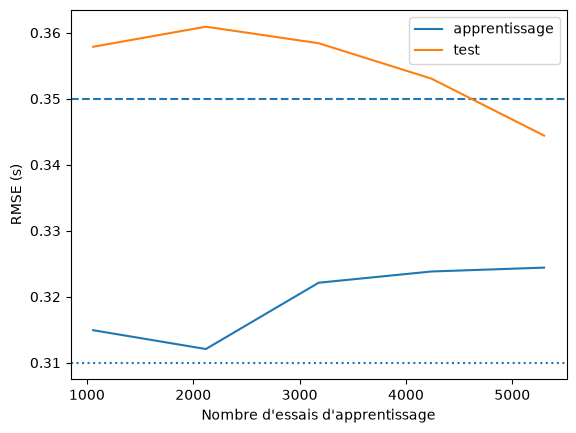

In [169]:
from sklearn.model_selection import learning_curve
mod = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
                ("reg", Ridge(alpha=1e4))])
tailles, scores_train, scores_test = learning_curve(mod, puissance_log, y, groups=groupes, cv=gkf, train_sizes=np.linspace(0.2, 1.0, 5), scoring="neg_root_mean_squared_error")
moyenne_test = (-scores_test).mean(axis=1)
moyenne_train = (-scores_train).mean(axis=1)

plt.plot(tailles,moyenne_train, label="apprentissage")
plt.xlabel("Nombre d'essais d'apprentissage")
plt.ylabel("RMSE (s)")
plt.axhline(0.35, linestyle="--")
plt.axhline(0.31, linestyle=":")
plt.plot(tailles,moyenne_test, label="test")
plt.legend()

### Courbe d'apprentissage (Ridge, puissance par bande)

Je regarde si le modèle s'améliore quand on lui donne plus d'essais d'apprentissage, avec `learning_curve` et le même `GroupKFold` que partout ailleurs. Le modèle est le `Pipeline` (imputation, `StandardScaler`, `Ridge` avec `alpha = 10 000`). Je trace le RMSE d'apprentissage et de test pour 5 tailles, de 20 % à 100 % des essais d'apprentissage disponibles (environ 180 à 900 essais).

**Premier essai avec `alpha = 10`.** L'erreur de test dépasse 1 s, avec une courbe irrégulière (de 1,7 à 1,0 s), alors que l'erreur d'apprentissage reste autour de 0,2 s : le modèle est en sur-ajustement et prédit n'importe quoi pour les sujets inconnus. La courbe ne se lit pas bien dans ce régime.

**Avec `alpha = 10 000`.**
- Le RMSE de test reste entre 0,356 et 0,385 s, c'est-à-dire **au-dessus de la baseline « moyenne » (0,35 s)** et loin de l'âge seul (0,31 s), à toutes les tailles.
- Il ne baisse pas quand on ajoute des essais.
- Le RMSE d'apprentissage est autour de 0,29 à 0,31 s : l'écart avec le test est faible.

**Lecture.** Avec ces features, ajouter des essais ne semble pas améliorer le modèle. Le blocage vient plutôt des features que du nombre d'essais. Les points sont toutefois bruités (4 sujets par pli de test), donc je n'exclus pas qu'un jeu de données avec plus de sujets aide. Cette courbe ne le prédit pas.

**Suite.** Tester une famille de features qui garde l'information de temps : la moyenne du signal par tranche de 200 ms après le stimulus.

In [170]:

X_temps = X_fen[:, :128, :].reshape(-1, 128, 10, 20).mean(axis=3).reshape(-1, 128 * 10)
print(X_temps.shape)
alpha = [1, 100, 1e4, 1e6, 1e7]

ligne=[]
for k in alpha:
    mod = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
                ("reg", Ridge(alpha=k))])
    scores = cross_val_score(mod, X_temps, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    ligne.append({"alpha": k, "rmse_moyen": (-scores).mean(), "rmse_pire": (-scores).max(), "rmse_meilleur": (-scores).min()})
test = pd.DataFrame(ligne)


print(test.head(30))



(6613, 1280)


/Users/OlivierDJEZVEDJIAN/Documents/APT/IODAA/vguigue/eeg-foundation-challenge/.venv/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.04496024277978e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/OlivierDJEZVEDJIAN/Documents/APT/IODAA/vguigue/eeg-foundation-challenge/.venv/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.41825169572985e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/OlivierDJEZVEDJIAN/Documents/APT/IODAA/vguigue/eeg-foundation-challenge/.venv/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0694500218733083e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


        alpha  rmse_moyen  rmse_pire  rmse_meilleur
0         1.0    8.945269  16.940305       0.759842
1       100.0    1.729336   3.320352       0.399752
2     10000.0    0.491292   0.974464       0.333911
3   1000000.0    0.347471   0.369538       0.330787
4  10000000.0    0.343212   0.357486       0.330837


In [171]:
scores = cross_val_score(modele, X_temps, y, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
print(scores)

[-0.32856645 -0.35493605 -0.36337835 -0.3520787  -0.33827085]


c'est toujours pas fou crentrons par sujet

In [172]:
centre = pd.DataFrame(puissance_log).groupby(groupes).transform("mean")
centrey=pd.DataFrame(y).groupby(groupes).transform("mean")

puissance_log_c = pd.DataFrame(puissance_log)-centre
y_c = pd.DataFrame(y)-centrey

print(puissance_log_c.shape, y_c.mean())

puissance_log_c = puissance_log_c.values.ravel()
y_c = y_c.values.ravel()




(6613, 640) 0   -2.854044e-18
dtype: float64


In [173]:
alpha = [1, 100, 1e4, 1e6, 1e7]

ligne=[]
for k in alpha:
    mod = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
                ("reg", Ridge(alpha=k))])
    scores = cross_val_score(mod, puissance_log_c, y_c, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
    ligne.append({"alpha": k, "rmse_moyen": (-scores).mean(), "rmse_pire": (-scores).max(), "rmse_meilleur": (-scores).min()})
test = pd.DataFrame(ligne)


print(test.head(30))
print("chiffre à battre :", np.sqrt((y_c**2).mean()))


modele = xgb.XGBRegressor()



scores = cross_val_score(modele, puissance_log_c, y_c, groups=groupes, cv=gkf,
                         scoring="neg_root_mean_squared_error")
print(scores)


ValueError: Found input variables with inconsistent numbers of samples: [4232320, 6613]

Essayons les réseaux de neuronnes

In [ ]:
import torch
from braindecode.models import EEGNeX

model = EEGNeX(n_chans=129, n_outputs=1, n_times=200, sfreq=100)


/Users/OlivierDJEZVEDJIAN/Documents/APT/IODAA/vguigue/eeg-foundation-challenge/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/Users/OlivierDJEZVEDJIAN/Documents/APT/IODAA/vguigue/eeg-foundation-challenge/.venv/lib/python3.11/site-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


In [ ]:

x_test = torch.tensor(X_fen[:8] * 1e6, dtype=torch.float32)   # 8 fenêtres, en µV
print(x_test.shape)          # (8, 129, 200)
print(model(x_test).shape)   # doit donner (8, 1)   



NameError: name 'X_fen' is not defined